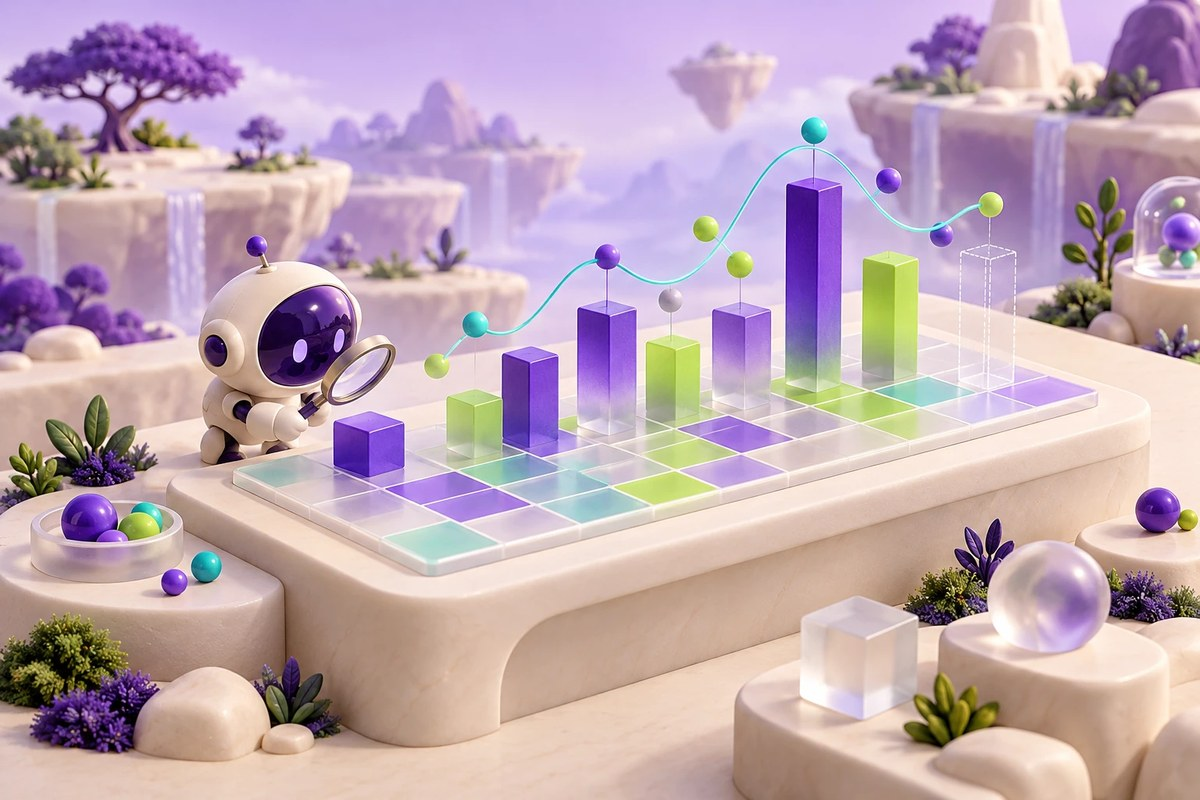

AI PATH · Данные и классификация · Урок 020

# Распределения: вероятность, ожидание и квантили

Дискретные исходы, нормальный закон и равномерное ожидание

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-020-goal"></a>
## Что вы разберёте

Выбирать распределение по условиям задачи и связывать PDF, CDF и PPF с конкретным вопросом.

### Перед началом

- Доли и вероятность события
- Среднее и стандартное отклонение
- Функции Python и словари

### Что понадобится

- Python с Pandas, SciPy, NumPy и Matplotlib
- Все параметры задач заданы в ноутбуке; внешние данные не требуются
- CPU достаточно; сеть нужна только если библиотеки ещё не установлены

## Навигация по уроку

- [Цель и подготовка](#ai-020-goal)
- [Карта урока](#ai-020-map)
- [Составить закон числа попаданий](#ai-020-section-01)
- [Разобрать математическое ожидание](#ai-020-section-02)
- [Вычислить вероятность интервала](#ai-020-section-03)
- [Выбрать равномерную модель ожидания](#ai-020-section-04)
- [Проверить переход от недели к дню](#ai-020-section-05)
- [Связать моменты и квантили](#ai-020-section-06)
- [Сравнить PDF и CDF на графике](#ai-020-section-07)
- [Посчитать выбор без возвращения](#ai-020-section-08)
- [Проверьте понимание](#ai-020-practice)
- [Источники и ограничения](#ai-020-provenance)

<a id="ai-020-map"></a>
## Карта урока

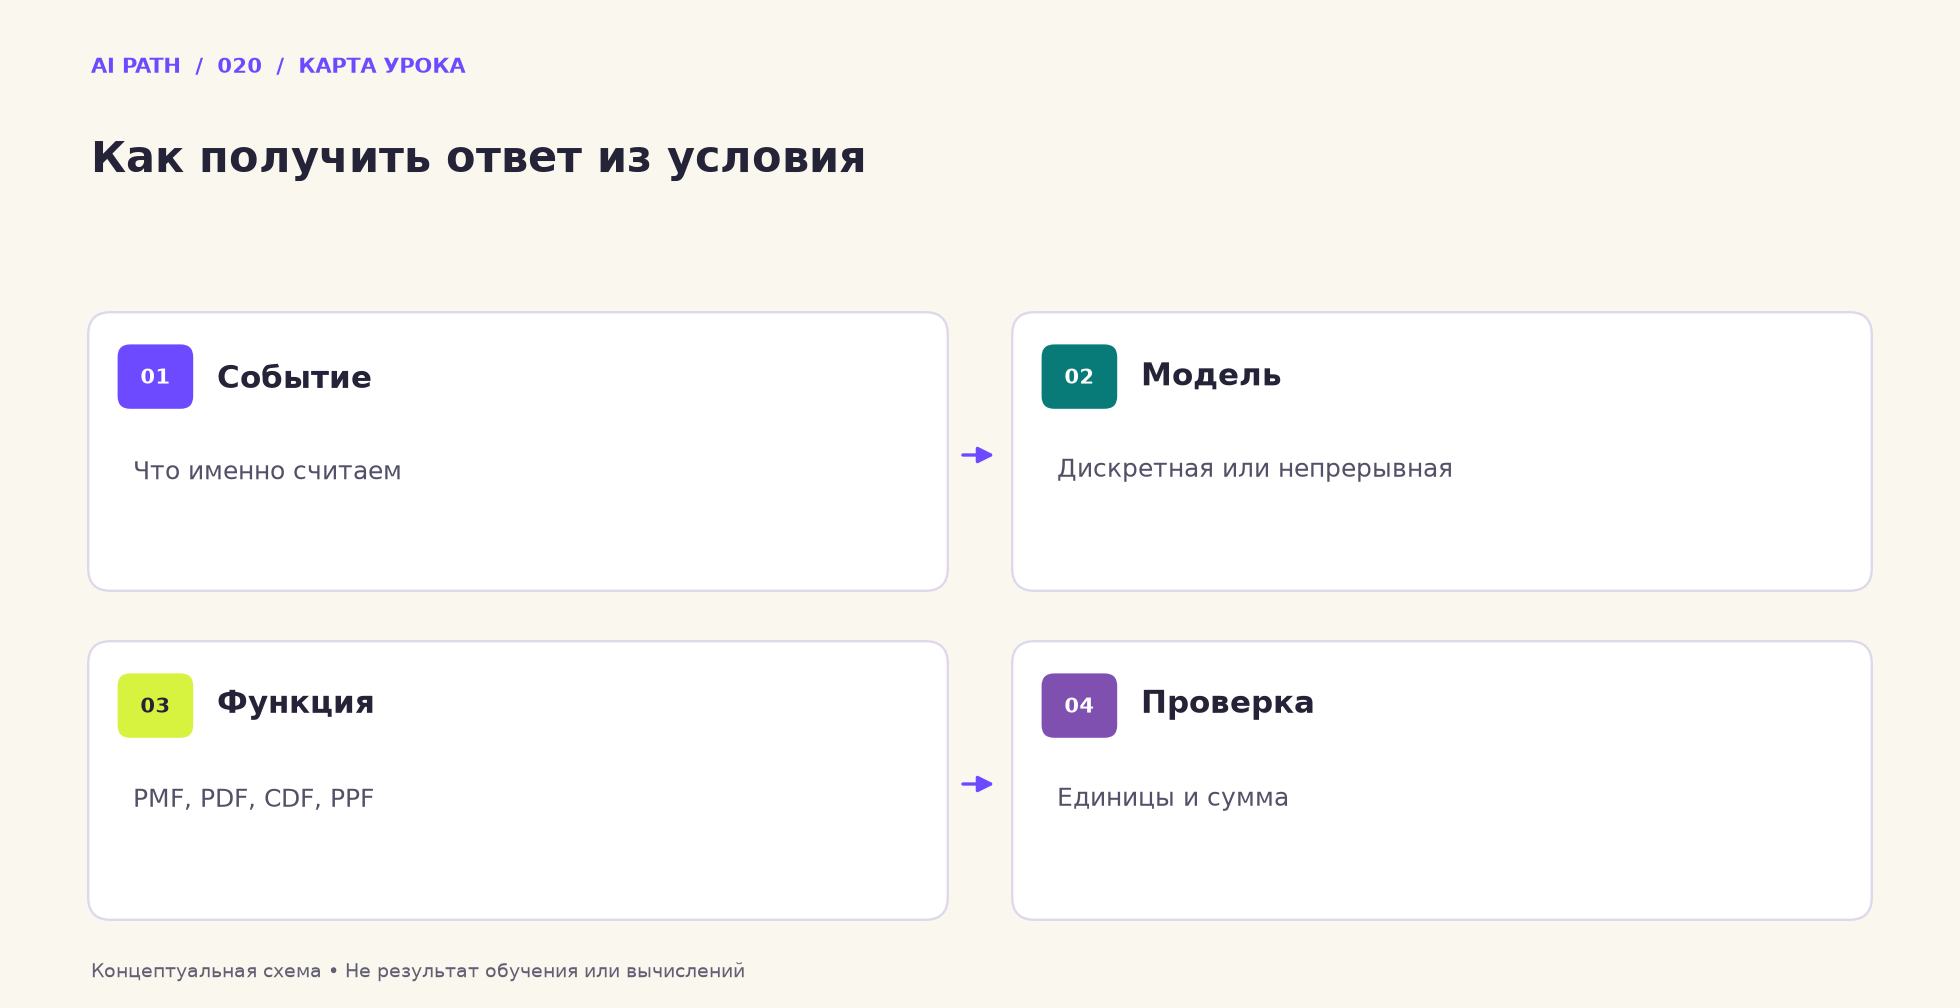

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Событие** — Что именно считаем
2. **Модель** — Дискретная или непрерывная
3. **Функция** — PMF, PDF, CDF, PPF
4. **Проверка** — Единицы и сумма

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90_%D0%90_%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%D0%B2%D0%B5%D1%80%D0%BE%D1%8F%D1%82%D0%BD%D0%BE%D1%81%D1%82%D0%B8_2%22%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#**Light**

<a id="ai-020-section-01"></a>
## 01 · Составить закон числа попаданий

Для двух независимых выстрелов перечислите 0, 1, 2 попадания. Проверьте сумму вероятностей до обсуждения среднего.

_Далее — исходные ячейки учебного материала._

Задача 1

Вероятность того, что стрелок поразит мишень, равна 0.7 

Составить закон распределения случайной величины  W – количества попаданий после 2 выстрелов.

In [ ]:
# Имеем ТРИ исхода:
# A1 - стрелок 2 раза промахнулся
# A2 - стрелок попал оба раза
# A3 - стрелок попал один раз а один промахнулся

P_a1 = (1-0.7)*(1-0.7)
P_a2 = 0.7*0.7
print ("0:{}".format(P_a1))
print ("2:{}".format(P_a2))
# Вероятность A3 найдем через теорему о полной группе вероятностей
P_a3 = 1-(P_a1+P_a2)
print ("1:{}".format(P_a3))
W={0:P_a1, 1:P_a3, 2:P_a2}
print(W)

0:0.09000000000000002
2:0.48999999999999994
1:0.42000000000000004
{0: 0.09000000000000002, 1: 0.42000000000000004, 2: 0.48999999999999994}


<a id="ai-020-section-02"></a>
## 02 · Разобрать математическое ожидание

Рулетка — учебный пример суммы «значение × вероятность». Отделите распределение одной ставки от результата короткой серии; это не рекомендация играть.

_Далее — исходные ячейки учебного материала._

Задача 2

Мистер Хэ играет в европейскую рулетку по следующей системе: постоянно ставит 250 рублей на «красное». 
Составить закон распределения случайной величины  – его выигрыша. 

Вычислить математическое ожидание выигрыша и округлить его. 

Сколько в среднем проигрывает игрок с каждой ставки?

In [ ]:
# Количество исходов на рулетке:
#37 = 36(18 красное и 18 черное) + 1 zero

In [ ]:
import pandas as pd

In [ ]:
# Мистер Хэ выигрывает 250 рублей в 18 случаях из 37, следовательно закон распределения его выигрыша имеет следующий вид:
w={250:18/37., -250:19/37.}
data = pd.DataFrame([w])
print(data)

# Вычислим математическое ожидание: M(x) = p1*x1 + p2*x2
mm = [ key * w[key] for key in w.keys()]
print("Мат ожидание игры: {} рубля".format(round(sum(mm),2)))
print("С каждой поставленной ставки игрок в среднем проигрывает: {} рубля".format(abs(round(sum(mm),2))))


        250      -250
0  0.486486  0.513514
Мат ожидание игры: -6.76 рубля
С каждой поставленной ставки игрок в среднем проигрывает: 6.76 рубля


<a id="ai-020-section-03"></a>
## 03 · Вычислить вероятность интервала

Для нормальной ошибки используется разность CDF. Проверьте границы ±6 и единицы стандартного отклонения.

_Далее — исходные ячейки учебного материала._

Задача 3

Случайная величина  ошибки взвешивания распределена по нормальному закону с нулевым математическим ожиданием и стандартным отклонением 4 грамма. Найти вероятность того, что очередное взвешивание будет проведено с ошибкой, не превышающей по модулю 6 грамм.

In [ ]:
from scipy.stats import norm
p = norm (0, 4).cdf(6)- norm(0,4).cdf(-6) # /
print('Вероятность того, что очередное взвешивание будет проведено с ошибкой, не превышающей по модулю 6 грамм.: {}'.format ( p))

Вероятность того, что очередное взвешивание будет проведено с ошибкой, не превышающей по модулю 6 грамм.: 0.8663855974622838


<a id="ai-020-section-04"></a>
## 04 · Выбрать равномерную модель ожидания

Постоянный интервал движения и равномерный момент прихода дают равномерное ожидание. Плотность и вероятность интервала — разные величины.

_Далее — исходные ячейки учебного материала._

Задача 4

Автобусы некоторого маршрута идут строго по расписанию и интервалом 5 минут. Составить функцию плотности случайной величины  X – времени ожидании очередного автобуса пассажиром, который наудачу подошёл к остановке. Найти вероятность того, что он будет ждать автобус не более 2x минут. 

In [ ]:
# Дискретная или непрерывная?
# Время можно разделить на сколь угодно малый интервал - следовательно случайная величина непрерывная.
# Из условия нам известно что автобусы ходят СТРОГО по расписанию, следовательно в значении функции плотности КОНСТАНТА и мы имеем дело с РАВНОМЕРНЫМ распределением

# Попробуем вывести PDF
# 0 -  если х  от -inf до 0
# 1/5 - если х  от 0 до 5
# 0 если x > 5

# А теперь проверим корректность снова выведя PDF на этот раз через формулы и свойства плотности вероятности
#=========
# Запишем PDF
# 0 -  если х  от -inf до 0
# C - если х  от 0 до 5
# 0 если x > 5

# Теперь мы можем легко найти C по формуле для равномерного распределения C = 1/b-a , где b=5 и a=0
C = 1/(5.-0)
print (' Const = {}'.format(C))

# Перепишем PDF
# 0   - если х  от -inf до 0
# 0.2 - если х  от 0 до 5
# 0   - если x > 5

# Теперь вычислим вероятность прождать не более 2-х минут: (вероянтность на интервале 0,2)

from scipy.stats import uniform
p = uniform(loc=0,scale=5).cdf(2)   # Значения разбросаны на интервале от 0 до 5, это и указываем
print('Вероятность того, что он будет ждать автобус не более 2x минут: {}'.format ( p))

 Const = 0.2
Вероятность того, что он будет ждать автобус не более 2x минут: 0.4


Задача 5

Рост мальчиков возрастной группы 15 лет есть нормально распределённая
случайная величина X с мат.ожиданием роста 161 см и среднеквадратичным отклонением 4 см. Какую долю костюмов для мальчиков, имеющих рост от 152 до 158 см, нужно предусмотреть в объёме производства для данной возрастной группы. 


In [ ]:
from scipy.stats import norm
p = norm (161, 4).cdf(158)- norm(161,4).cdf(152) # Считаем CDF для 158 и CDF для 152 
print('Доля костюмов для мальчиков, имеющих рост от 152 до 158 см: {}%'.format (round(100 * p, 3)))

Доля костюмов для мальчиков, имеющих рост от 152 до 158 см: 21.44%


<a id="ai-020-section-05"></a>
## 05 · Проверить переход от недели к дню

Исходник делит и mean, и std на 7, но это не следует из данных о недельной сумме. Сначала сформулируйте модель дневных чисел брака и зависимость между днями.

_Далее — исходные ячейки учебного материала._

# Pro 1

Задача 6

На машиностроительном заводе в процессе производства за неделю обнаруживается, в среднем, 100 бракованных деталей, со среднеквадричным отклонением равным 12 деталям. 
Рассчитать: 
1)
Вероятность того, что за неделю будет 20-30 бракованных деталей
2)
Вероятность того, что за день будет хотя бы одна забракованная деталь.

In [ ]:
mu = 100
std = 12

dist = norm(mu, std)
F = dist.cdf

print("Искомая вероятность а): {}".format(F(30)-F(20))) 

# Вычисляем вероятность возникновения хотя бы одного брака за день
mu /=7
std /=7
dist = norm(mu, std)
F = dist.cdf

#P(a<X) = 1-P(-inf<x<A) = 1-cdf(A)

print("Искомая вероятность б): {}".format(1-F(1)))  # На основе упомянутого свойства найдем вероятноть противоположного события: будет хотя бы 1 брак

Искомая вероятность а): 2.7034598124020633e-09
Искомая вероятность б): 0.9999999999999954


<a id="ai-020-section-06"></a>
## 06 · Связать моменты и квантили

stats даёт среднее и дисперсию, ppf возвращает значение по накопленной вероятности. Сверьте единицы каждого ответа.

_Далее — исходные ячейки учебного материала._

Задача 7

Для задач 3 - 6 Вычислить среднее, дисперсию и 0.25 и 0.9 квантили

In [ ]:
# Для решения этой задачи воспользуемся готовой библиотекой scipy
from scipy.stats import poisson, norm, uniform
dist_list = [] # Пустой лист куда запишется распределение с нужными параметрами

# Задаем распределения Задачи 3 и добавляем в dist_list
mu = 0
sigm = 4
norm_ = norm(mu,sigm)
dist_list.append(norm_)

# Задаем распределения Задачи 4 и добавляем в dist_list
unif = uniform(loc=0,scale=5)
dist_list.append(unif)

# Задаем распределения Задачи 5 и добавляем в dist_list
mu = 161
sigm = 4
norm_ = norm(mu,sigm)
dist_list.append(norm_)

# Задаем распределения Задачи 6 и добавляем в dist_list
mu = 100
std = 12
gaus1 = norm(mu, std)
dist_list.append(gaus1)


# Задаем функцию для расчета моментов распределения
def dist_moments(dist_):
  mean, var,_,_ = dist_.stats(moments='mvsk')
  print("Среднее: {}".format(mean))                    # Среднее
  print("Вариация: {}".format(var))                    # Дисперсия 
  print("Перцентиль 0.25: {}".format(dist_.ppf(0.25))) # Квантиль 25%
  print("Перцентиль 0.9: {}".format(dist_.ppf(0.9)))   # Квантиль 90%


# Теперь проходимся циклом по всем распределениям
for i,d in enumerate(dist_list):
  print("Для Задачи: {}".format(i+3))
  dist_moments(d)
  print('====================')

Для Задачи: 3
Среднее: 0.0
Вариация: 16.0
Перцентиль 0.25: -2.697959000784327
Перцентиль 0.9: 5.1262062621784015
Для Задачи: 4
Среднее: 2.5
Вариация: 2.083333333333333
Перцентиль 0.25: 1.25
Перцентиль 0.9: 4.5
Для Задачи: 5
Среднее: 161.0
Вариация: 16.0
Перцентиль 0.25: 158.30204099921568
Перцентиль 0.9: 166.1262062621784
Для Задачи: 6
Среднее: 100.0
Вариация: 144.0
Перцентиль 0.25: 91.90612299764702
Перцентиль 0.9: 115.3786187865352


<a id="ai-020-section-07"></a>
## 07 · Сравнить PDF и CDF на графике

Одна кривая описывает плотность, другая накопленную вероятность. Границы осей и достоверные подписи важнее визуальной формы.

_Далее — исходные ячейки учебного материала._

Задача 8

Для задач 3 - 6 Построить графики cdf и pdf

In [ ]:
import  matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm, uniform

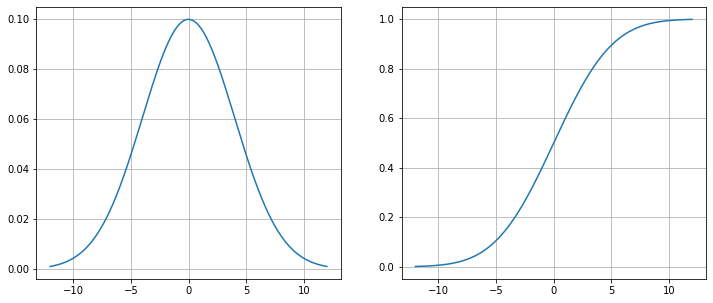

In [ ]:
#3
mu = 0  # Мат. ожидание
std = 4 # Среднее квадротичное отклонение
x = np.linspace(mu-3*std, mu+3*std, 1000)
f = norm(mu, std).pdf(x)
F = norm(mu, std).cdf(x)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(x, f)
ax[0].grid()
ax[1].plot(x, F)
ax[1].grid()

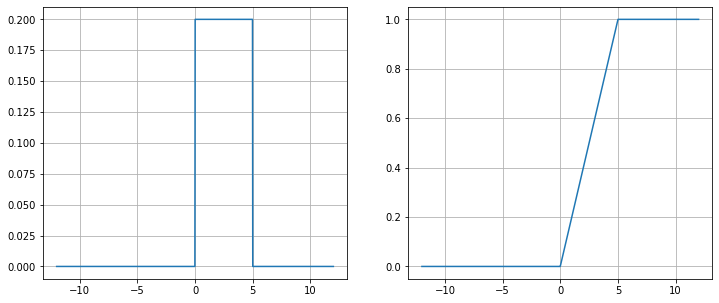

In [ ]:
#4
import numpy as np
import matplotlib.pyplot as plt
x = np.linspace(-12, 12, 1000)
f = uniform(0, 5).pdf(x)
F = uniform(0, 5).cdf(x)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(x, f)
ax[0].grid()
ax[1].plot(x, F)
ax[1].grid()
plt.show()

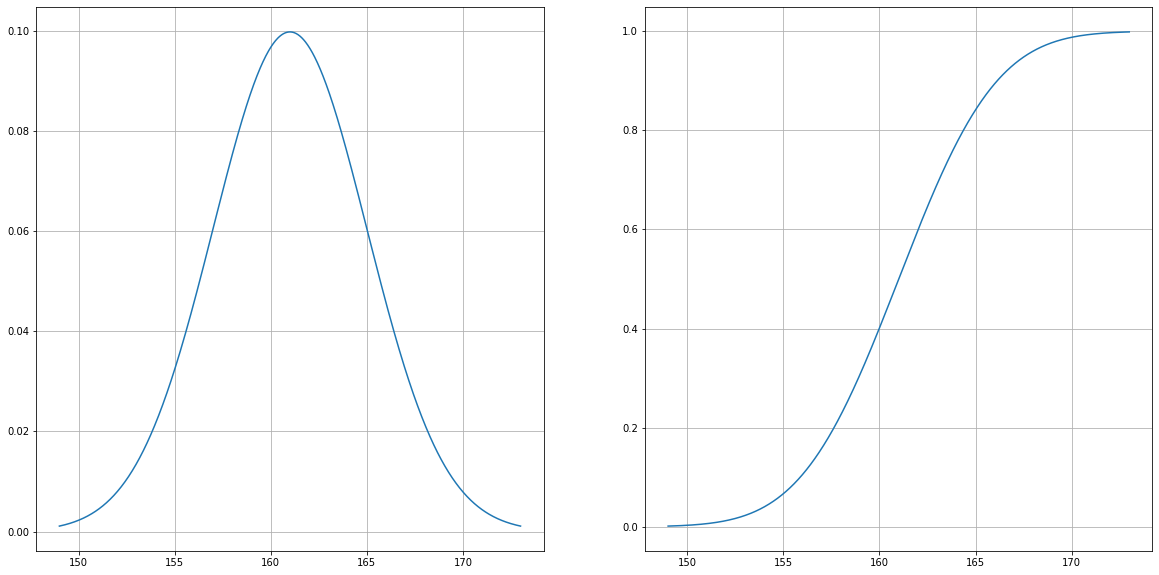

In [ ]:
#5
mu = 161
std = 4
x = np.linspace(mu-3*std, mu+3*std, 1000)
f = norm(mu, std).pdf(x)
F = norm(mu, std).cdf(x)
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].plot(x, f)
ax[0].grid()
ax[1].plot(x, F)
ax[1].grid()

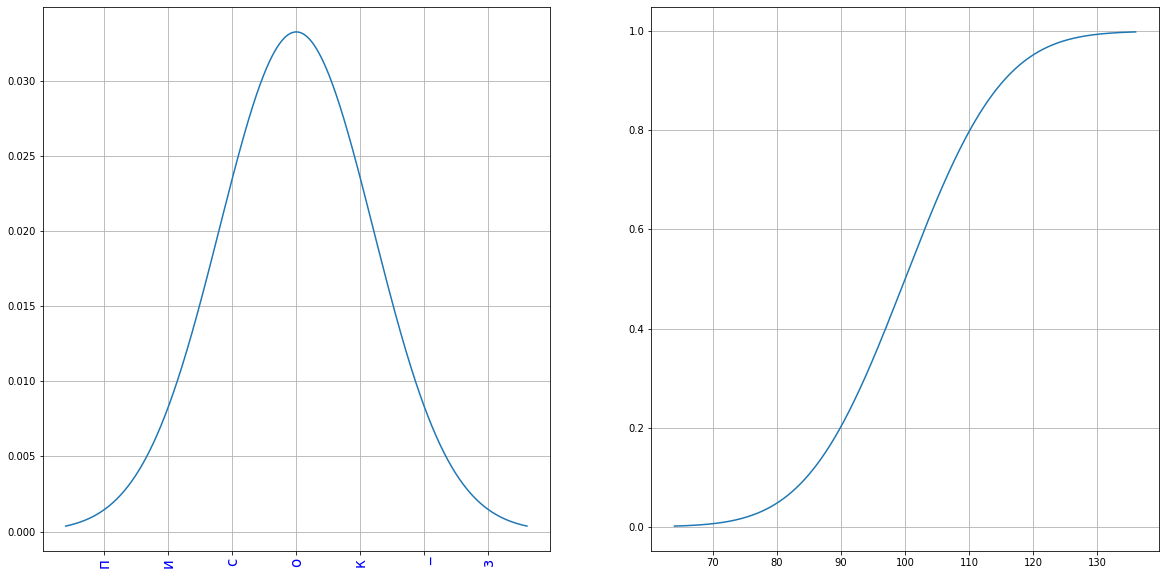

In [ ]:
#6
mu = 100
std = 12
x = np.linspace(mu-3*std, mu+3*std, 1000)
f = norm(mu, std).pdf(x)
F = norm(mu, std).cdf(x)
fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].plot(x, f)
ax[0].set_xticklabels('список_значений',
                   fontsize = 15,   
                   color = 'b',    
                   rotation = 90)
ax[0].grid()
ax[1].plot(x, F)
ax[1].grid()

<a id="ai-020-section-08"></a>
## 08 · Посчитать выбор без возвращения

После извлечения первой детали меняется состав коробки. Сумма трёх случаев служит отдельной проверкой расчёта.

_Далее — исходные ячейки учебного материала._

Задача 9

В ящике находится 17 качественных и 6 бракованных деталей. Наудачу извлекаются 2 детали. Найти вероятность того, что:

a) обе детали будут качественными;
b) одна деталь будет качественной, а одна – бракованной;
c) обе детали бракованны.

In [ ]:
n = 23 # Всего деталей 23, после извлечения одной детали остается 22
p1= 17./n * 16./(n-1) 
p2= (17./n * 6./(n-1)) + (6./n *17/(n-1))
p3= 6./n * 5./(n-1)

print (sum([p1,p2,p3])) # проверка, по формуле полной вероятности сумма = 1
W={2:p1, 1:p2, 0:p3}
print(W)

1.0
{2: 0.5375494071146245, 1: 0.4031620553359684, 0: 0.05928853754940711}


<a id="ai-020-practice"></a>
## Проверьте понимание

1. Проверьте сумму вероятностей для двух выстрелов и двух деталей.
2. Объясните разницу CDF(6)-CDF(-6) и PDF(6).
3. Покажите, какие дополнительные предположения нужны, чтобы перейти от недельной статистики брака к дневной.

### Один самостоятельный эксперимент

Для равномерного ожидания с интервалом 5 минут сравните аналитическую CDF с частотами в моделировании при фиксированном seed.

**Критерий успеха:** Сравнены несколько порогов внутри и вне [0, 5]; объяснена погрешность конечной симуляции; плотность не названа вероятностью точки.

<a id="ai-020-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/ML/%D0%A1%D0%B0%D1%84%D0%BE%D0%BD%D0%BE%D0%B2_%D0%90_%D0%90_%D0%A2%D0%B5%D0%BE%D1%80%D0%B8%D1%8F_%D0%B2%D0%B5%D1%80%D0%BE%D1%8F%D1%82%D0%BD%D0%BE%D1%81%D1%82%D0%B8_2%22%22.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Пересчёт недельного std делением на 7 не обоснован. Для суммы независимых одинаково распределённых дней масштаб std был бы другим, а сама независимость не установлена.
- Для счётного числа дефектов нормальная модель требует обоснования; событие «хотя бы 1» нельзя безоговорочно заменить непрерывным 1-CDF(1).
- Ячейка 24 задаёт строковые ticklabels без согласованного Locator, что может вызвать предупреждение или несоответствие подписей.
- Новый прогон не выполнен; примеры — заданные математические модели, а не эмпирические данные производства.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.